[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/15-projects/p03-digit-recognizer-cnn/colab_quickstart.ipynb)

# P3 quickstart - digit recogniser: MLP vs CNN in PyTorch

This notebook downloads the project (in Colab), installs its packages, runs it and shows the results. Locally it uses the folder you already have. CPU is enough (2-3 minutes); a Colab GPU is not needed.

## 1. Get the code
In Colab this clones the repo. If the project folder already exists, the clone is skipped.

In [1]:
import os, subprocess, sys
from pathlib import Path

PROJECT = "15-projects/p03-digit-recognizer-cnn"
if Path("main.py").exists() and Path("requirements.txt").exists():
    print("Already inside the project folder - no clone needed.")
elif Path("../../" + PROJECT).exists():
    os.chdir("../../" + PROJECT)          # repo already on disk two levels up
else:
    if not Path("AI-Engineer").exists():  # first run in Colab: download the repo
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/vvvvvivekkk/AI-Engineer.git"], check=True)
    os.chdir(Path("AI-Engineer") / PROJECT)
print("Working folder:", Path.cwd())

Already inside the project folder - no clone needed.
Working folder: /home/claude/AI-Engineer/15-projects/p03-digit-recognizer-cnn


## 2. Install packages (Colab only)

In [2]:
import sys, subprocess
from pathlib import Path
# Only install in Colab. Locally you already did "pip install -r requirements.txt" in a venv.
# Colab ships its own PyTorch, so we skip the torch line to save a big download.
if "google.colab" in sys.modules:
    reqs = [l for l in Path("requirements.txt").read_text().splitlines()
            if l.strip() and not l.startswith(("#", "torch"))]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *reqs], check=True)
    print("installed", len(reqs), "packages")
else:
    print("Not in Colab - skipping install.")

Not in Colab - skipping install.


## 3. (Re)create the sample data
Saves the 1,797 bundled digit images to data/digits.csv.

In [3]:
!{sys.executable} make_data.py

wrote data/digits.csv: 1797 images of 8x8 pixels


## 4. Train the MLP and the CNN
Early stopping ends training when validation loss stops improving.

In [4]:
!{sys.executable} main.py

train 1257 | validation 270 | test 270 images


MLP  test accuracy 0.970 | 8 wrong | 9,610 params | stopped after 60 epochs (best 60) | 77.7s


CNN  test accuracy 0.978 | 6 wrong | 38,282 params | stopped after 40 epochs (best 32) | 191.5s


charts + summary.json written to /home/claude/AI-Engineer/15-projects/p03-digit-recognizer-cnn/reports


## 5. Look at the results
Loss curves, the CNN's confusion matrix, its mistakes and its learned filters.

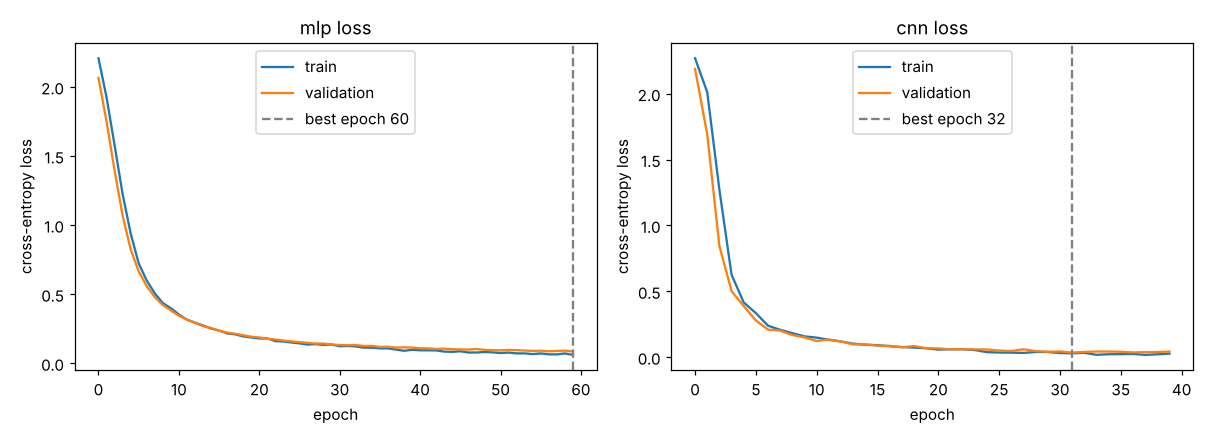

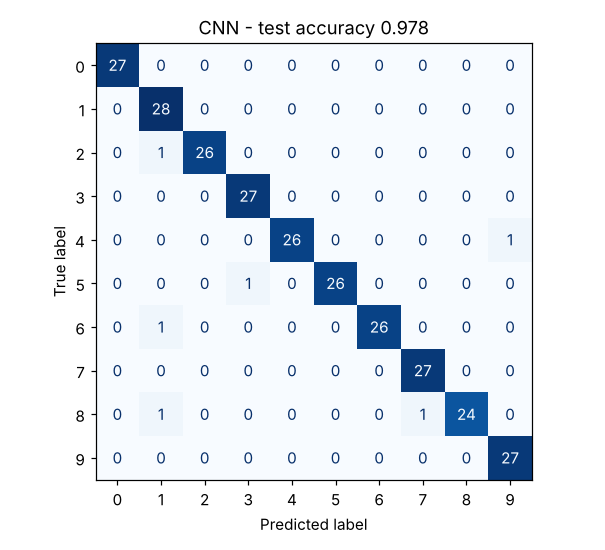

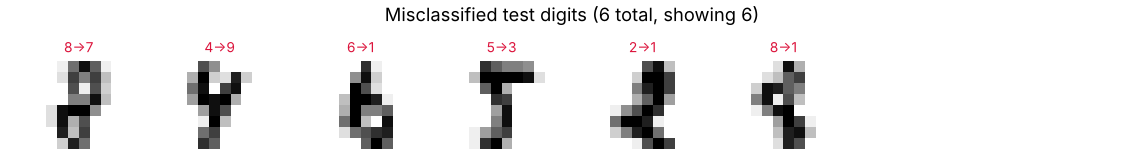

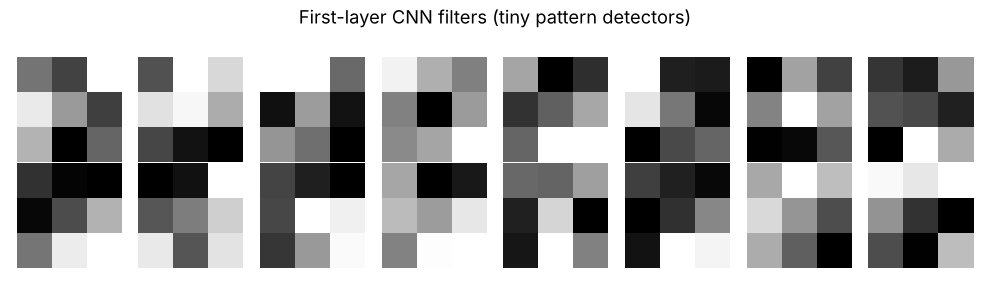

In [5]:
from IPython.display import Image, display
for f in ['loss_curves', 'confusion_cnn', 'misclassified_cnn', 'cnn_filters']:
    display(Image(f'reports/{f}.png'))

## 6. Run the tests
`pytest` runs every function whose name starts with `test_`.

In [6]:
!{sys.executable} -m pytest -q

.

..

.                                                                     [100%]
4 passed in 28.71s
